In [1]:
import kagglehub
import torch

path = "data/CIFAR10"


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda:0")
    elif torch.backends.mps.is_available():
        return torch.device("mps")
    else:
        return torch.device("cpu")


device = get_device()



In [3]:
from torchvision import datasets, transforms

datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/"
    "VerisimilitudeX/cifar10/resolve/main/"
    "cifar-10-python.tar.gz"
)

transform = transforms.Compose([
    transforms.ToTensor(),
])

train_ds = datasets.CIFAR10(
    root=path,
    train=True,
    download=True,
    transform=transform
)

test_ds = datasets.CIFAR10(
    root=path,
    train=False,
    download=True,
    transform=transform
)

In [4]:
import numpy as np

X_train = train_ds.data
y_train = np.array(train_ds.targets)

X_test = test_ds.data
y_test = np.array(test_ds.targets)

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

print("dtype:", X_train.dtype)
print("Min:", X_train.min())
print("Max:", X_train.max())
print("Mean:", X_train.mean())
print("Std:", X_train.std())

Train: (50000, 32, 32, 3) (50000,)
Test: (10000, 32, 32, 3) (10000,)
dtype: uint8
Min: 0
Max: 255
Mean: 120.70756512369792
Std: 64.1500758911213


## Проверка качества данных
Проверим полноту, допустимость значений и дубликаты. Для изображений CIFAR-10 «пропуски» и выбросы имеют иной смысл, чем для табличных признаков: нельзя удалять необычные пиксели как ошибочные без дополнительной проверки.

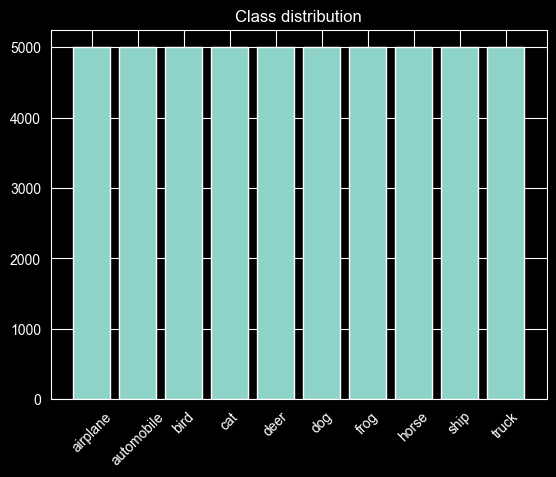

In [5]:
import matplotlib.pyplot as plt

classes = train_ds.classes
counts = np.bincount(y_train, minlength=10)

plt.bar(classes, counts)
plt.xticks(rotation=45)
plt.title("Class distribution")
plt.show()

Как видно на диаграмме, класс сбалансированы.

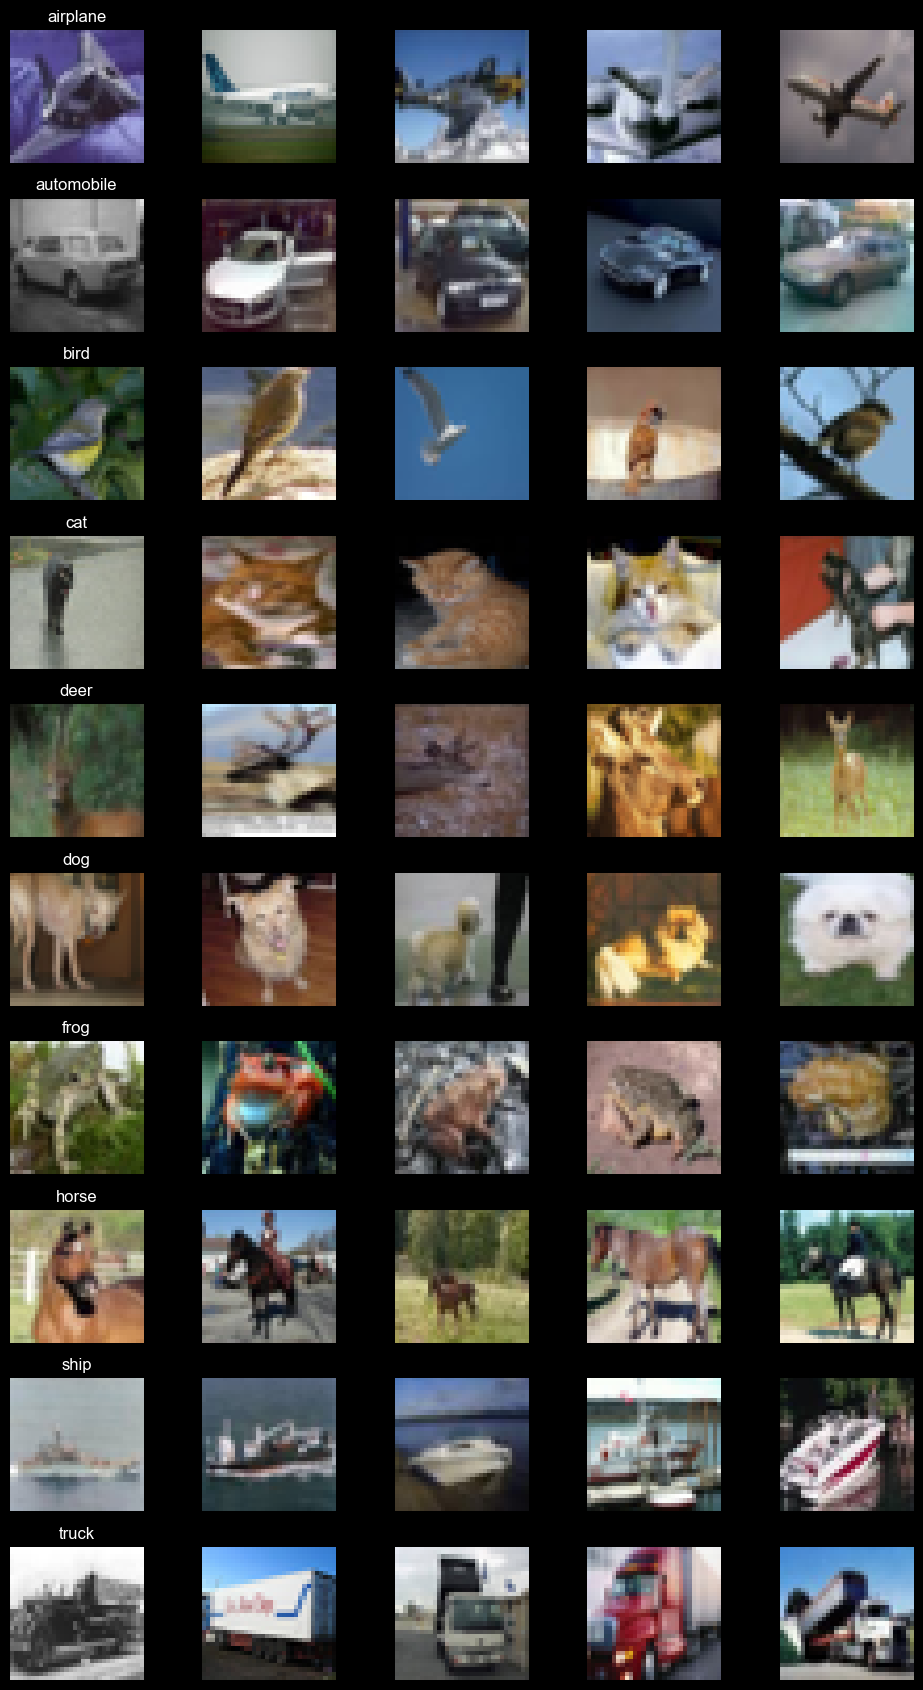

In [6]:
fig, axes = plt.subplots(10, 5, figsize=(10, 17))

rng = np.random.default_rng(42)

for class_id in range(10):
    indices = np.where(y_train == class_id)[0]
    selected = rng.choice(indices, size=5, replace=False)

    for j, idx in enumerate(selected):
        axes[class_id, j].imshow(X_train[idx])
        axes[class_id, j].axis("off")

        if j == 0:
            axes[class_id, j].set_title(classes[class_id])

plt.tight_layout()
plt.show()

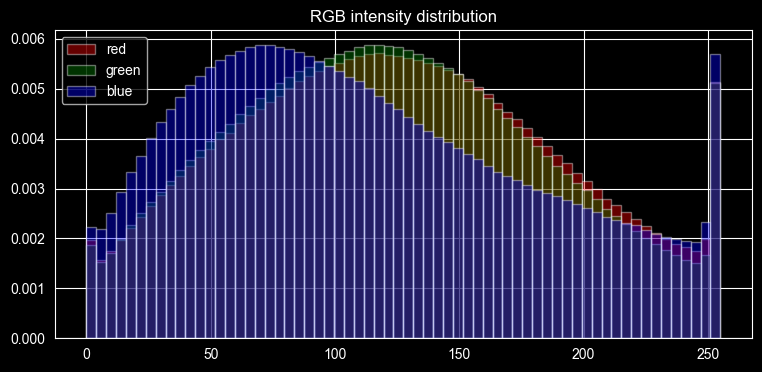

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))

for i, color in enumerate(["red", "green", "blue"]):
    ax.hist(
        X_train[:, :, :, i].ravel(),
        bins=64,
        alpha=0.4,
        color=color,
        density=True,
        label=color,
    )

ax.legend()
ax.set_title("RGB intensity distribution")
plt.show()

Распределения интенсивностей RGB-каналов CIFAR-10 имеют различную форму. Синий канал характеризуется смещением в сторону меньших значений интенсивности относительно красного и зелёного. Для всех каналов наблюдается широкий диапазон значений и заметная концентрация на отдельных участках, включая максимальную интенсивность 255.

## Сравнение train и test
Сопоставим распределения интенсивности по RGB-каналам. Это базовая проверка на заметный сдвиг распределений, но совпадение гистограмм само по себе не доказывает, что выборки эквивалентны.

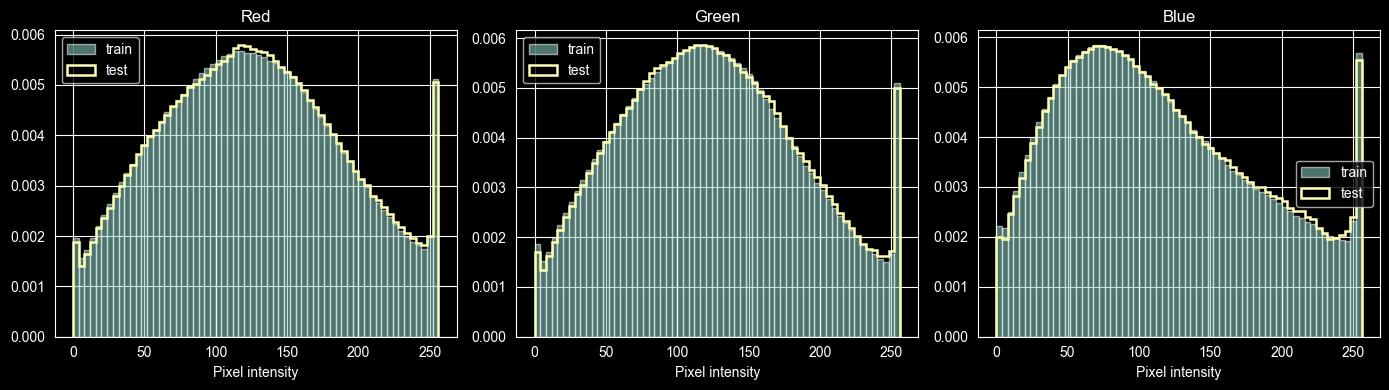

train RGB mean: [125.31 122.95 113.87] RGB std: [62.99 62.09 66.7 ]
test RGB mean: [126.02 123.71 114.85] RGB std: [62.9  61.94 66.71]


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for c, name in enumerate(("Red", "Green", "Blue")):
    axes[c].hist(X_train[..., c].ravel(), bins=64, range=(0, 256),
                 density=True, alpha=0.55, label="train")
    axes[c].hist(X_test[..., c].ravel(), bins=64, range=(0, 256),
                 density=True, histtype="step", linewidth=1.8, label="test")
    axes[c].set_title(name)
    axes[c].set_xlabel("Pixel intensity")
    axes[c].legend()
plt.tight_layout()
plt.show()

for split, X in [("train", X_train), ("test", X_test)]:
    print(split, "RGB mean:", X.mean(axis=(0, 1, 2)).round(2),
          "RGB std:", X.std(axis=(0, 1, 2)).round(2))


Распределения интенсивности RGB каналов совпадают, что указывает на отсутствие заметного сдвига между train и test. Средние значения и стандартные отклонения также близки.

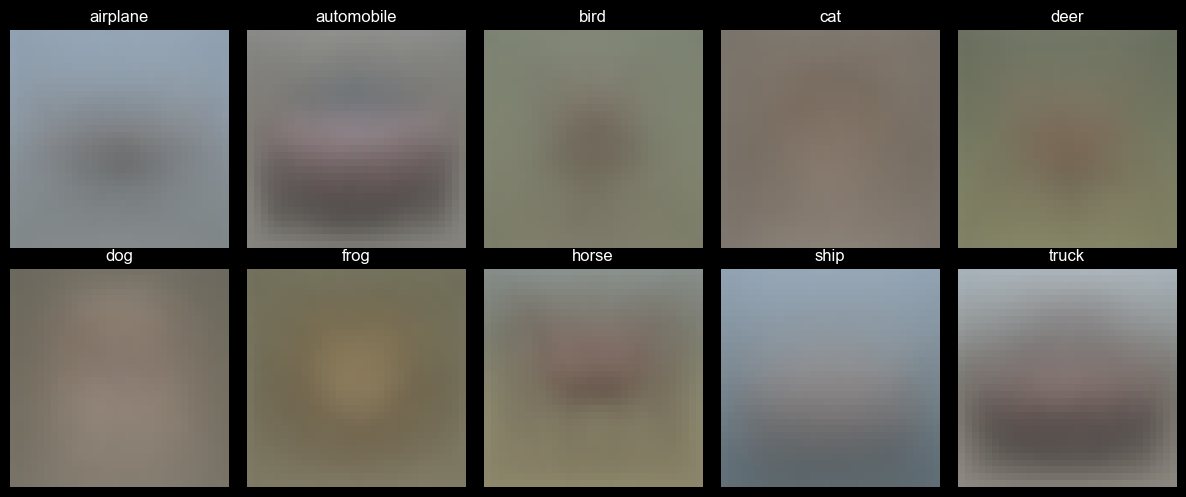

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_id, ax in enumerate(axes.flat):
    mean_image = X_train[y_train == class_id].mean(axis=0) / 255.0

    ax.imshow(mean_image)
    ax.set_title(classes[class_id])
    ax.axis("off")

plt.tight_layout()
plt.show()

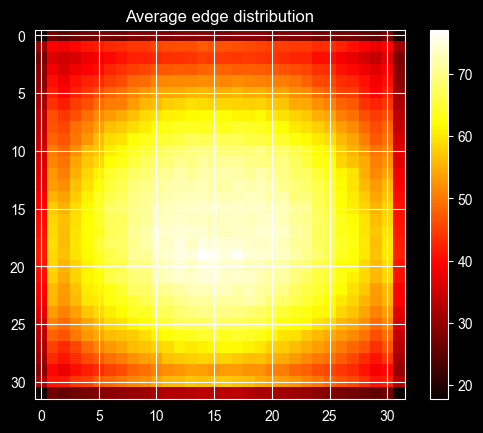

In [10]:
import cv2

edges = []

for img in X_train:
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    edge = cv2.Canny(gray, 100, 200)
    edges.append(edge)

mean_edges = np.mean(edges, axis=0)

plt.imshow(mean_edges, cmap="hot")
plt.colorbar()
plt.title("Average edge distribution")
plt.show()

Усреднённая карта границ изображений CIFAR-10 демонстрирует выраженную пространственную неоднородность. Наибольшая частота обнаружения границ наблюдается в центральной области изображений, тогда как ближе к краям и особенно в углах она заметно снижается.

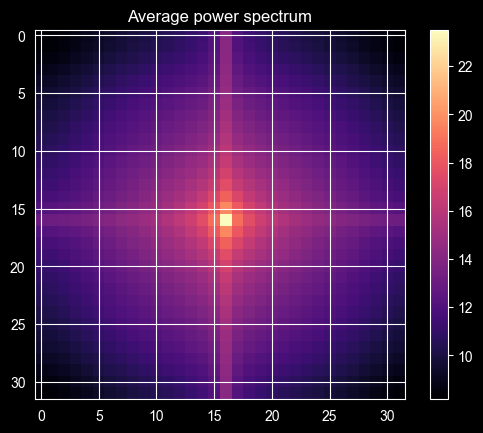

In [11]:
gray = X_train.mean(axis=3).astype(np.float32)

fft = np.fft.fft2(gray, axes=(1, 2))
fft = np.fft.fftshift(fft, axes=(1, 2))

power = np.abs(fft) ** 2
mean_power = power.mean(axis=0)

plt.imshow(np.log1p(mean_power), cmap="magma")
plt.colorbar()
plt.title("Average power spectrum")
plt.show()

Усреднённый энергетический спектр изображений CIFAR-10 демонстрирует преобладание низких пространственных частот. По мере удаления от центра спектра наблюдается снижение средней спектральной мощности.

Также заметна неравномерность распределения энергии по направлениям, выраженная вертикальной и горизонтальной полосами через центр спектра. Это может быть связано как со структурой изображений, так и с особенностями применения дискретного преобразования Фурье.



## Характеристики изображений относительно класса
Анализируем числовые характеристики относительно целевой переменной: класса изображения. Сравним яркость, контраст и плотность границ на уровне отдельных изображений.

,n,brightness_mean,contrast_mean,edge_density_mean
class,,,,
frog,5000,111.496002,43.351002,0.259
truck,5000,124.567001,60.742001,0.248
deer,5000,116.584999,41.261002,0.214
automobile,5000,116.961998,57.444000,0.250
bird,5000,123.196999,41.481998,0.188
horse,5000,122.219002,53.337002,0.237
ship,5000,132.145996,51.763000,0.178
cat,5000,118.176003,52.256001,0.220
dog,5000,119.775002,52.247002,0.216


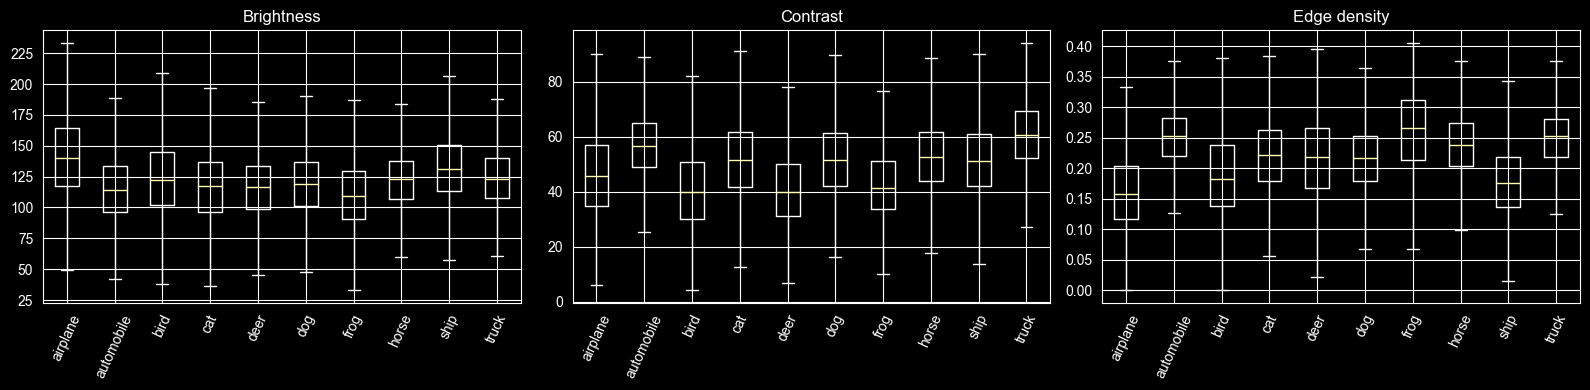

In [12]:
import pandas as pd

# Относительная яркость (приближение для sRGB) и контраст как std яркости
luma = (0.299 * X_train[..., 0].astype(np.float32)
        + 0.587 * X_train[..., 1].astype(np.float32)
        + 0.114 * X_train[..., 2].astype(np.float32))

# Массив edges вычислен в предыдущей ячейке с Canny
edge_density = np.asarray(edges, dtype=np.uint8).mean(axis=(1, 2)) / 255.0
features = pd.DataFrame({
    "class": [train_ds.classes[int(i)] for i in y_train],
    "brightness": luma.mean(axis=(1, 2)),
    "contrast": luma.std(axis=(1, 2)),
    "edge_density": edge_density,
})

class_stats = features.groupby("class", sort=False).agg(
    n=("brightness", "size"),
    brightness_mean=("brightness", "mean"),
    contrast_mean=("contrast", "mean"),
    edge_density_mean=("edge_density", "mean"),
)
display(class_stats.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, label in zip(
    axes,
    ("brightness", "contrast", "edge_density"),
    ("Brightness", "Contrast", "Edge density"),
):
    groups = [features.loc[features["class"] == cls, metric].values
              for cls in train_ds.classes]
    ax.boxplot(groups, labels=train_ds.classes, showfliers=False)
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()


## Dataset suitability and limitations

В качестве основного датасета для исследования выбран **CIFAR-10**, содержащий 60 000 цветных изображений размером 32×32 пикселя, разделённых на 10 сбалансированных классов.

### Обоснование выбора

1. **Цветовая информация.** В отличие от MNIST, CIFAR-10 содержит три цветовых канала, что позволяет исследовать влияние цветовых характеристик универсальных возмущений на эффективность атаки.

2. **Пространственная структура.** Изображения содержат объекты на разнообразных фонах, с различными положениями и масштабами. Это позволяет изучать пространственные закономерности UAP и их связь с характеристиками исходных изображений.

3. **Частотные характеристики.** Наличие текстур, границ и цветовых переходов позволяет исследовать распределение спектральной энергии и проверять гипотезы о влиянии частотной структуры возмущений на эффективность атаки.

4. **Вычислительная доступность.** Небольшое разрешение изображений снижает стоимость генерации UAP и позволяет проводить больше экспериментов с различными функциями потерь, архитектурами и стратегиями оптимизации.

### Ограничения

- **Низкое разрешение (32×32).** Ограничивает количество высокочастотных деталей и возможность исследования мелких пространственных структур.
- **Небольшое число классов.** Не позволяет в полной мере исследовать поведение UAP в задачах с большим количеством семантически близких категорий.
- **Ограниченная переносимость результатов.** Эффективность методов на CIFAR-10 не гарантирует аналогичного поведения на ImageNet и других датасетах с более высоким разрешением.

### Вывод

CIFAR-10 рассматривается как экспериментальная среда для первоначальной проверки гипотез о пространственных, цветовых и частотных характеристиках универсальных состязательных возмущений.

Полученные результаты позволят определить перспективные направления для дальнейших экспериментов. Проверка обобщаемости выявленных закономерностей на более сложных датасетах остаётся отдельной задачей.